In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
    davies_bouldin_score,
    confusion_matrix
)

# 字体配置
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 1. 读取上一步选优保存的 UMAP 降维数据
RESULT_FILE = Path('result') / 'fashion-umap-redu-result.npz'
assert RESULT_FILE.exists(), f"未找到文件: {RESULT_FILE}，请先运行 UMAP 降维脚本！"

with np.load(RESULT_FILE, allow_pickle=True) as data:
    X_umap = data['embedding']          # 聚类用的 UMAP 高维/最佳特征 (例如 5 维或更高)
    X_umap_2d = data['embedding_2d']    # 统一画图用的 2D 流形坐标
    y = data['labels']                  # 真实标签
    CLASS_NAMES = list(data['class_names'])
    SEED = int(data['seed'])
    params_info = {k: data[k].item() if data[k].ndim == 0 else data[k] 
                   for k in ['n_neighbors', 'min_dist', 'n_components', 'metric']}

print(f"数据加载成功！")
print(f"  聚类特征矩阵形状: {X_umap.shape}")
print(f"  2D可视化流形形状: {X_umap_2d.shape}")
print(f"  样本标签数量: {y.shape[0]}")
print(f"  UMAP选定参数: {params_info}")

数据加载成功！
  聚类特征矩阵形状: (7000, 5)
  2D可视化流形形状: (7000, 2)
  样本标签数量: 7000
  UMAP选定参数: {'n_neighbors': 30, 'min_dist': 0.1, 'n_components': 5, 'metric': 'cosine'}


In [2]:
all_eval_results = []
all_predictions = {}

# 针对轮廓系数计算，抽样 3000 点以加速并保证可比性
np.random.seed(SEED)
sub_idx = np.random.choice(len(X_umap), size=min(len(X_umap), 3000), replace=False)

def evaluate_and_plot(name, preds):
    # 1. 计算各项量化指标
    ari = adjusted_rand_score(y, preds)
    nmi = normalized_mutual_info_score(y, preds)
    score = (ari + nmi) / 2
    sil = silhouette_score(X_umap[sub_idx], preds[sub_idx])
    dbi = davies_bouldin_score(X_umap, preds)
    
    res = {
        '模型': name,
        '综合 score (↑)': score,
        'ARI (↑)': ari,
        'NMI (↑)': nmi,
        'Silhouette (↑)': sil,
        'DBI (↓)': dbi
    }
    all_eval_results.append(res)
    all_predictions[name] = preds
    
    # 2. 打印当前单模型指标卡
    df_single = pd.DataFrame([res]).set_index('模型')
    display(df_single.style.format('{:.3f}').set_caption(f'【{name}】在 UMAP 空间下的评估指标'))
    
    # 3. 绘制双联图：左侧 2D 流形簇分布，右侧 真实类别对应热力图
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    
    # 子图 1: 2D 散点图
    scatter = axes[0].scatter(X_umap_2d[:, 0], X_umap_2d[:, 1], c=preds, cmap='tab10', s=7, alpha=0.75)
    axes[0].set_title(f"{name} 聚类流形分布 (ARI: {ari:.3f})", fontsize=12, fontweight='bold')
    axes[0].axis('off')
    
    handles, _ = scatter.legend_elements(prop="colors", alpha=0.8)
    axes[0].legend(handles, [f"Cluster {i}" for i in range(10)], title="聚类簇标识",
                   loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=True, fontsize=9, markerscale=1.5)
    
    # 子图 2: 真实品类混淆热力图
    cm = confusion_matrix(y, preds)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axes[1],
                xticklabels=[f'C{i}' for i in range(10)], yticklabels=CLASS_NAMES)
    axes[1].set_title(f"{name} 真实品类分配纯度映射", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("聚类簇编号 (Cluster ID)")
    axes[1].set_ylabel("真实品类 (Ground Truth)")
    
    plt.tight_layout()
    plt.show()

print("评估函数与画图工具准备完毕。")

评估函数与画图工具准备完毕。


,综合 score (↑),ARI (↑),NMI (↑),Silhouette (↑),DBI (↓)
模型,,,,,
K-Means,0.563,0.477,0.650,0.556,0.625


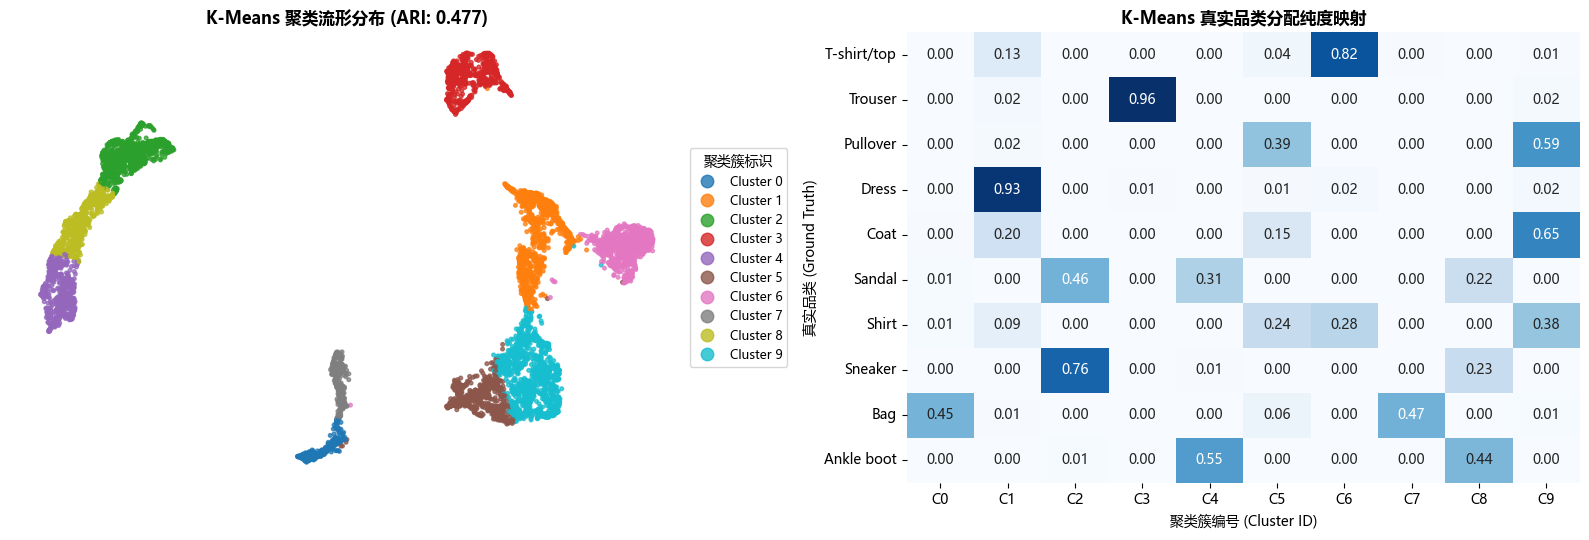

In [3]:
# 初始化并训练 K-Means 模型
kmeans = KMeans(n_clusters=10, n_init=10, random_state=SEED)
preds_kmeans = kmeans.fit_predict(X_umap)

# 评估并绘图
evaluate_and_plot('K-Means', preds_kmeans)

,综合 score (↑),ARI (↑),NMI (↑),Silhouette (↑),DBI (↓)
模型,,,,,
GMM,0.571,0.491,0.651,0.559,0.624


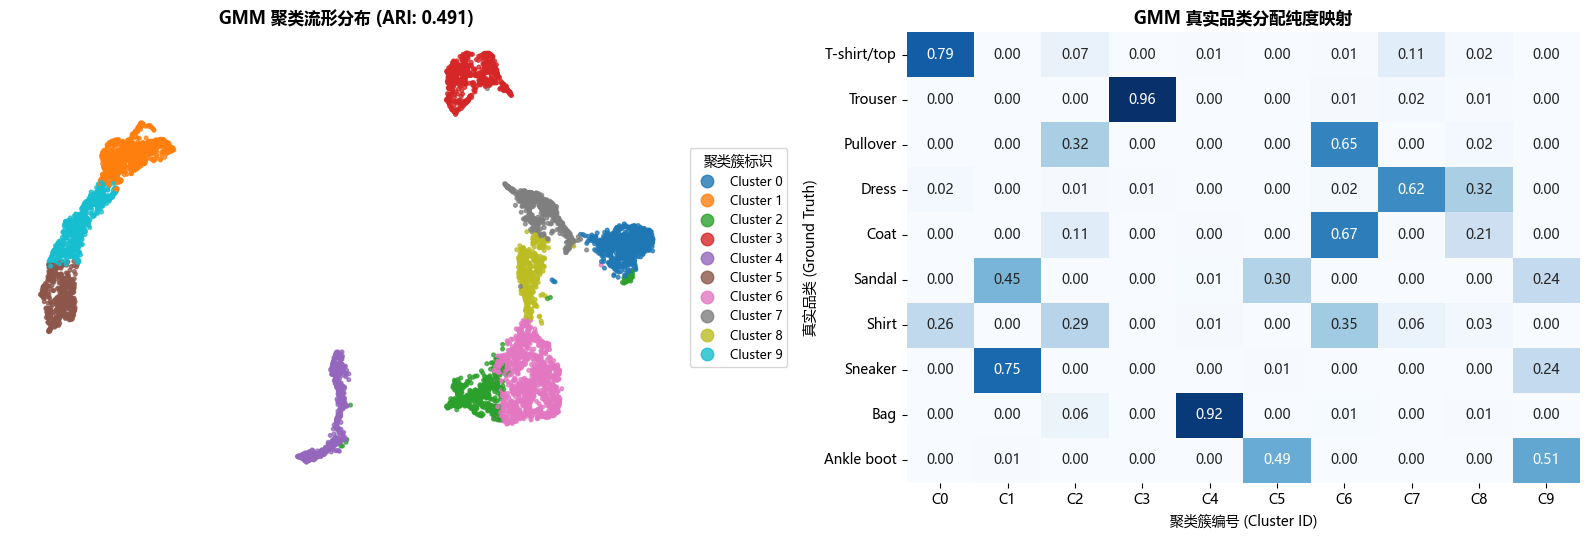

In [4]:
# 初始化并训练 GMM 模型
gmm = GaussianMixture(n_components=10, covariance_type='diag', random_state=SEED)
preds_gmm = gmm.fit_predict(X_umap)

# 评估并绘图
evaluate_and_plot('GMM', preds_gmm)

,综合 score (↑),ARI (↑),NMI (↑),Silhouette (↑),DBI (↓)
模型,,,,,
Agglomerative,0.577,0.490,0.665,0.561,0.563


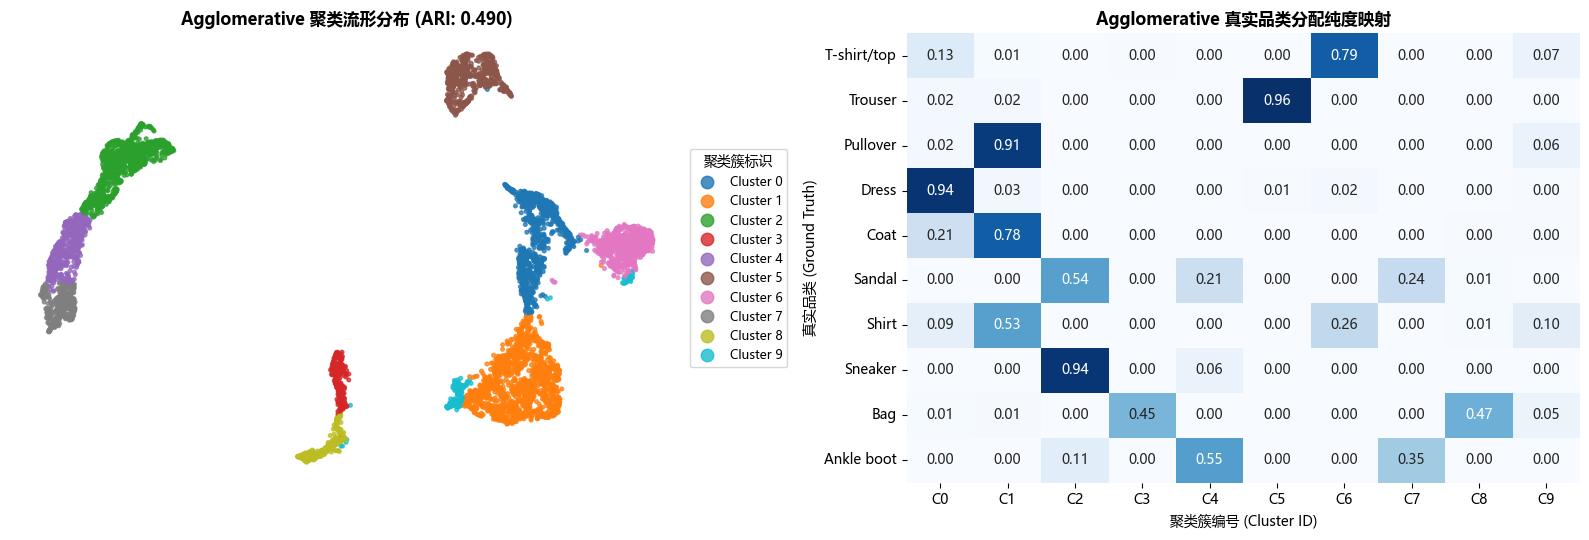

In [5]:
# 初始化并训练层次凝聚聚类模型 (ward 方差最小化准则)
agg = AgglomerativeClustering(n_clusters=10, linkage='ward')
preds_agg = agg.fit_predict(X_umap)

# 评估并绘图
evaluate_and_plot('Agglomerative', preds_agg)

,综合 score (↑),ARI (↑),NMI (↑),Silhouette (↑),DBI (↓)
模型,,,,,
K-Means,0.563,0.477,0.650,0.556,0.625
GMM,0.571,0.491,0.651,0.559,0.624
Agglomerative,0.577,0.490,0.665,0.561,0.563


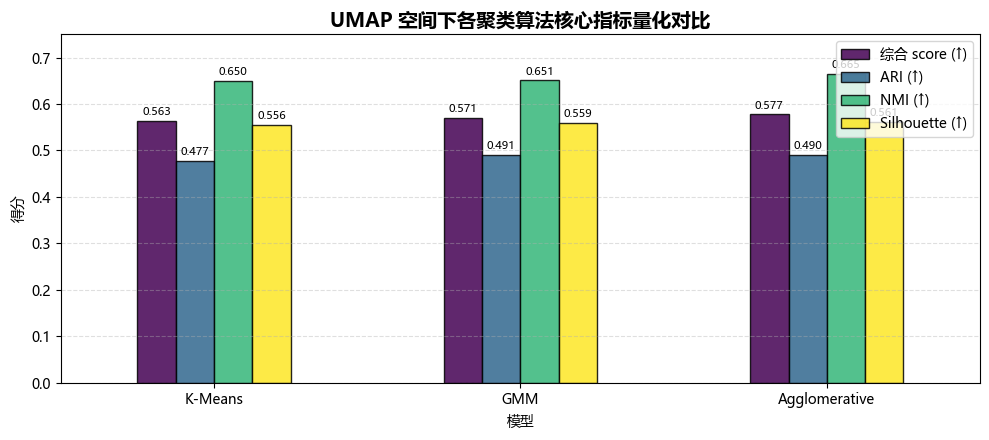

In [6]:
# 1. 生成并展示汇总总表
df_summary = pd.DataFrame(all_eval_results).set_index('模型')
display(df_summary.style.format('{:.3f}')
        .background_gradient(cmap='Greens', subset=['综合 score (↑)', 'ARI (↑)', 'NMI (↑)', 'Silhouette (↑)'])
        .background_gradient(cmap='Reds_r', subset=['DBI (↓)'])
        .set_caption('表 1  UMAP 空间下三大聚类模型性能量化对比表'))

# 2. 绘制多指标柱状图
fig, ax = plt.subplots(figsize=(10, 4.5))
metrics_plot = ['综合 score (↑)', 'ARI (↑)', 'NMI (↑)', 'Silhouette (↑)']
df_summary[metrics_plot].plot(kind='bar', ax=ax, rot=0, colormap='viridis', edgecolor='black', alpha=0.85)

ax.set_title("UMAP 空间下各聚类算法核心指标量化对比", fontsize=14, fontweight='bold')
ax.set_ylabel("得分")
ax.set_ylim(0, 0.75)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(frameon=True, loc='upper right')

# 在柱状图上方标注具体数值
for p in ax.patches:
    val = p.get_height()
    if val > 0.01:
        ax.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()